In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().reset_index(drop=True)

if "target" not in df.columns:
    raise ValueError("Dataset must contain a 'target' column.")

if df.isnull().values.any():
    raise ValueError("Handle missing values before training.")

X = df.drop(columns=["target"]).to_numpy(dtype=float)
y = df["target"].to_numpy()

if len(np.unique(y)) < 2:
    raise ValueError("At least two classes are required.")

In [3]:
rng = np.random.default_rng(42)

train_idx = []
test_idx = []

for label in np.unique(y):
    idx = np.where(y == label)[0]
    rng.shuffle(idx)

    n_test = max(1, int(round(0.2 * len(idx))))

    test_idx.extend(idx[:n_test])
    train_idx.extend(idx[n_test:])

train_idx = np.array(train_idx)
test_idx = np.array(test_idx)

rng.shuffle(train_idx)
rng.shuffle(test_idx)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Unique records:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Unique records: 302
Training samples: 241
Testing samples: 61


In [4]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1.0

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [5]:
class KNNClassifier:

    def __init__(self, k=5, chunk_size=128):
        if k < 1:
            raise ValueError("k must be at least 1.")

        self.k = k
        self.chunk_size = chunk_size

    def fit(self, X, y):
        if self.k > len(X):
            raise ValueError("k cannot exceed training size.")

        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)

        self.classes = np.unique(y)
        return self

    def pairwise_distances(self, A, B):
       
        a_sq = np.sum(A ** 2, axis=1, keepdims=True)
        b_sq = np.sum(B ** 2, axis=1)[None, :]

        distances_sq = a_sq + b_sq - 2 * (A @ B.T)
        distances_sq = np.maximum(distances_sq, 0.0)

        return np.sqrt(distances_sq)

    def _predict_one(self, distances):
        cutoff = np.partition(
            distances, self.k - 1
        )[self.k - 1]

        candidates = np.flatnonzero(distances <= cutoff)

        order = np.lexsort((
            candidates,
            distances[candidates]
        ))

        neighbors = candidates[order[:self.k]]

        neighbor_distances = distances[neighbors]
        neighbor_labels = self.y_train[neighbors]

        vote_counts = np.array([
            np.sum(neighbor_labels == label)
            for label in self.classes
        ])

        highest_votes = np.max(vote_counts)
        tied_classes = self.classes[
            vote_counts == highest_votes
        ]

        if len(tied_classes) == 1:
            prediction = tied_classes[0]
        else:
            total_distances = np.array([
                np.sum(neighbor_distances[
                    neighbor_labels == label
                ])
                for label in tied_classes
            ])

            minimum_distance = np.min(total_distances)

            closest_classes = tied_classes[
                np.isclose(
                    total_distances,
                    minimum_distance
                )
            ]

            prediction = np.min(closest_classes)

        return prediction

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predictions = []

        for start in range(0, len(X), self.chunk_size):
            X_chunk = X[start:start + self.chunk_size]

            distances = self.pairwise_distances(
                X_chunk, self.X_train
            )

            for row in distances:
                predictions.append(self._predict_one(row))

        return np.asarray(predictions)

In [7]:
def evaluate_model(y_true, y_pred):
    classes = np.unique(np.concatenate((y_true, y_pred)))

    confusion = np.zeros(
        (len(classes), len(classes)),
        dtype=int
    )

    for actual, predicted in zip(y_true, y_pred):
        actual_index = np.where(classes == actual)[0][0]
        predicted_index = np.where(classes == predicted)[0][0]
        confusion[actual_index, predicted_index] += 1

    accuracy = np.mean(y_true == y_pred)

    precisions = []
    recalls = []
    f1_scores = []

    for i in range(len(classes)):
        TP = confusion[i, i]
        FP = confusion[:, i].sum() - TP
        FN = confusion[i, :].sum() - TP

        precision = TP / (TP + FP) if TP + FP else 0.0
        recall = TP / (TP + FN) if TP + FN else 0.0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)

    return {
        "accuracy": accuracy,
        "precision_macro": np.mean(precisions),
        "recall_macro": np.mean(recalls),
        "f1_macro": np.mean(f1_scores),
        "confusion_matrix": confusion,
        "classes": classes
    }

In [8]:
# ==================================================
# 6. TRAIN AND TEST K-NN
# ==================================================

knn = KNNClassifier(k=5, chunk_size=64)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

metrics = evaluate_model(y_test, y_pred)

print("\nK-NN Results")
print("=" * 40)
print(f"Accuracy:       {metrics['accuracy']:.4f}")
print(f"Macro Precision:{metrics['precision_macro']:.4f}")
print(f"Macro Recall:   {metrics['recall_macro']:.4f}")
print(f"Macro F1 Score: {metrics['f1_macro']:.4f}")

print("\nConfusion Matrix")
print("Class order:", metrics["classes"])
print(metrics["confusion_matrix"])


K-NN Results
Accuracy:       0.8689
Macro Precision:0.8709
Macro Recall:   0.8653
Macro F1 Score: 0.8671

Confusion Matrix
Class order: [0 1]
[[23  5]
 [ 3 30]]


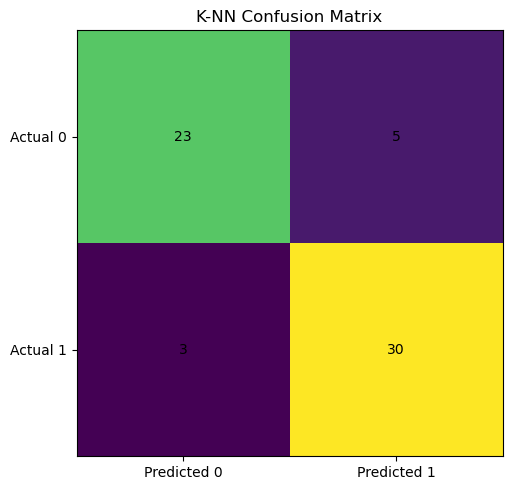

In [9]:
# ==================================================
# 7. PLOT CONFUSION MATRIX
# ==================================================

plt.figure(figsize=(6, 5))
plt.imshow(metrics["confusion_matrix"])

classes = metrics["classes"]

plt.xticks(
    range(len(classes)),
    [f"Predicted {c}" for c in classes]
)
plt.yticks(
    range(len(classes)),
    [f"Actual {c}" for c in classes]
)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j, i,
            str(metrics["confusion_matrix"][i, j]),
            ha="center",
            va="center"
        )

plt.title("K-NN Confusion Matrix")
plt.tight_layout()
plt.show()


Comparison of k values
 k  accuracy  macro_f1
 1    0.7705    0.7674
 3    0.8197    0.8179
 5    0.8689    0.8671
 7    0.8689    0.8671
 9    0.8689    0.8671
11    0.8852    0.8841
15    0.8689    0.8659


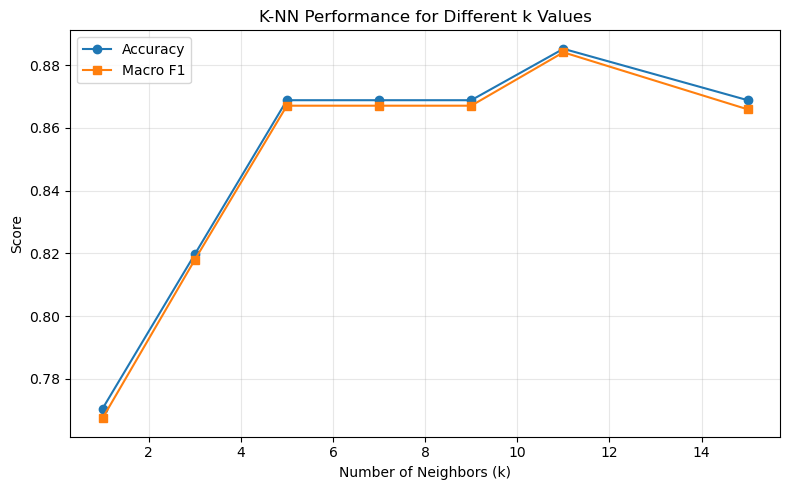

In [10]:
k_values = [1, 3, 5, 7, 9, 11, 15]
k_results = []

for k in k_values:
    if k > len(X_train):
        continue

    model = KNNClassifier(k=k, chunk_size=64)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    scores = evaluate_model(y_test, predictions)

    k_results.append({
        "k": k,
        "accuracy": scores["accuracy"],
        "macro_f1": scores["f1_macro"]
    })

results_df = pd.DataFrame(k_results)

print("\nComparison of k values")
print(results_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(
    results_df["k"],
    results_df["accuracy"],
    marker="o",
    label="Accuracy"
)
plt.plot(
    results_df["k"],
    results_df["macro_f1"],
    marker="s",
    label="Macro F1"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Score")
plt.title("K-NN Performance for Different k Values")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
output = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

output.to_csv("manual_knn_predictions.csv", index=False)

results_df.to_csv(
    "manual_knn_k_comparison.csv",
    index=False
)

print("\nSaved predictions and k comparison results.")


Saved predictions and k comparison results.
